In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import auc
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

c:\Users\SYC\Desktop\ml\ml-zoomcamp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
df=pd.read_csv('data/course_lead_scoring_2026.csv')

In [21]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [22]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [23]:
categorical=["lead_source","industry","employment_status","location"]
numerical=["annual_income","number_of_courses_viewed","interaction_count","lead_score","converted"]

In [24]:
df[categorical]=df[categorical].fillna("NA")
df[numerical]=df[numerical].fillna(0)

In [25]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [26]:
#df.converted=(df.converted=="yes").astype(int)

In [27]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [28]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [29]:
y_train=df_train.converted.values
y_val=df_val.converted.values
y_test=df_test.converted.values

In [30]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

##### Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.

Use the training dataset for that

If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- lead_score
- number_of_courses_viewed
- interaction_count
- annual_income

**Respuesta: lead_score** 

In [31]:
numeric=["annual_income","number_of_courses_viewed","interaction_count","lead_score"]

for col in numeric:
    score=roc_auc_score(y_train,df_train[col])
    if score<0.5:
        score=1-roc_auc_score(y_train,-df_train[col])
    print(f'{col}: {score:.3f}')

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


##### Question 2: training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

**Respuesta: 0.732**

In [32]:
train_dicts=df_train[numeric+categorical].to_dict(orient='records')
val_dicts=df_val[numeric+categorical].to_dict(orient='records')

dv=DictVectorizer(sparse=False)

X_train=dv.fit_transform(train_dicts)
X_val=dv.transform(val_dicts)

In [33]:
model=LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [34]:
y_pred=model.predict_proba(X_val)[:,1]

In [35]:
auc = roc_auc_score(y_val, y_pred)
print(f'AUC: {round(auc, 3)}')

AUC: 0.732


##### Question 3: Precision and Recall
Now let's compute precision and recall for our model.

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01

For each threshold, compute precision and recall
Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- 0.73
- 0.83

**Respuesta: 0.63**

In [41]:
#matriz de confusión 
scores=[]
thresholds=np.linspace(0,1,101)

for t in thresholds:
    actual_positive=(y_val==1)
    actual_negative=(y_val==0)
    predicted_positive=(y_pred>=t)
    predicted_negative=(y_pred<t)
    tp=(predicted_positive & actual_positive).sum() #true positives
    tn=(predicted_negative & actual_negative).sum() #true negatives
    fp=(predicted_positive & actual_negative).sum() #false positives
    fn=(predicted_negative & actual_positive).sum() #false negatives
    precision=tp/(tp+fp)
    recall=tp/(tp+fn)
    accuracy=(tp+tn)/len(y_val)
    scores.append((t,tp,fp,fn,tn,precision,recall,accuracy))

df_scores=pd.DataFrame(scores,columns=['threshold','tp','fp','fn','tn','precision','recall','accuracy'])

<positron-console-cell-41>:14: RuntimeWarning: invalid value encountered in scalar divide


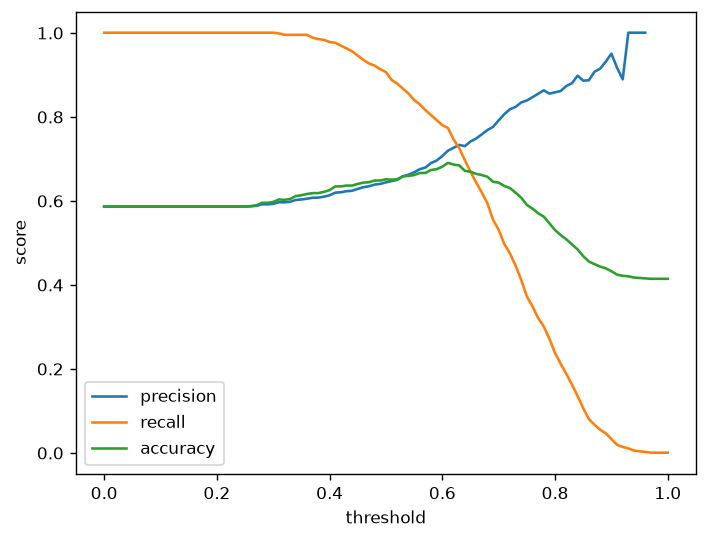

In [43]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.plot(df_scores.threshold, df_scores.accuracy, label='accuracy')
plt.xlabel('threshold')
plt.ylabel('score')
plt.legend()
plt.show()

##### Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_{1}=2.\frac{P.R}{P+R}$$

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

**Respuesta: 0.41**

In [44]:
#matriz de confusión 
scores_f1=[]
thresholds=np.linspace(0,1,101)

for t in thresholds:
    actual_positive=(y_val==1)
    actual_negative=(y_val==0)
    predicted_positive=(y_pred>=t)
    predicted_negative=(y_pred<t)
    tp=(predicted_positive & actual_positive).sum() #true positives
    tn=(predicted_negative & actual_negative).sum() #true negatives
    fp=(predicted_positive & actual_negative).sum() #false positives
    fn=(predicted_negative & actual_positive).sum() #false negatives
    precision=tp/(tp+fp)
    recall=tp/(tp+fn)
    accuracy=(tp+tn)/len(y_val)
    f1=2*(precision*recall)/(precision+recall)
    scores_f1.append((t,tp,fp,fn,tn,precision,recall,accuracy,f1))

df_scores_f1=pd.DataFrame(scores_f1,columns=['threshold','tp','fp','fn','tn','precision','recall','accuracy','f1'])

<positron-console-cell-44>:14: RuntimeWarning: invalid value encountered in scalar divide


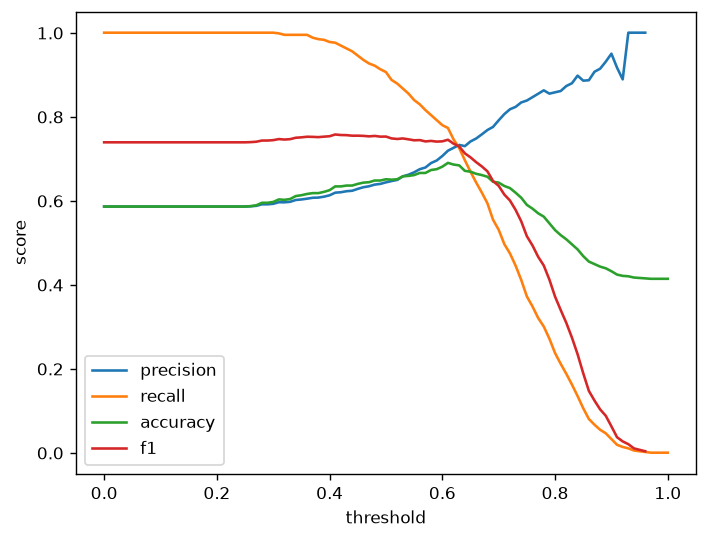

In [45]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.plot(df_scores.threshold, df_scores.accuracy, label='accuracy')
plt.plot(df_scores_f1.threshold, df_scores_f1.f1, label='f1')
plt.xlabel('threshold')
plt.ylabel('score')
plt.legend()
plt.show()

##### Question 5: 5-Fold CV
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)

Iterate over different folds of df_full_train

Split the data into train and validation

Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

**Respuesta: 0.007**

In [47]:
def train(df,y_train,C=1.0):
    dicts=df[categorical+numeric].to_dict(orient='records') # convertir dataframe a una lista de diccionarios

    dv=DictVectorizer(sparse=False) # DictVectorizer es una clase que transforma un diccionario de datos en una matriz de características. La opción sparse=False indica que queremos una matriz densa en lugar de una matriz dispersa.
    X_train=dv.fit_transform(dicts) #fit_transform lo que hace es primero ajustar el modelo a los datos (fit) y luego transformar los datos (transform) en una matriz de características.

    model=LogisticRegression(solver='liblinear',C=C,max_iter=1000) #max_inter es el número máximo de iteraciones que se permiten para que el algoritmo converja. Si no converge, se puede aumentar este número.
    model.fit(X_train,y_train)

    return dv,model

def predict(df,dv,model):
    dicts=df[categorical+numeric].to_dict(orient='records')
    X=dv.transform(dicts)
    y_pred=model.predict_proba(X)[:,1] #predict_proba devuelve una matriz con las probabilidades de cada clase. [:,1] selecciona la columna de probabilidades de la clase positiva.

    return y_pred

In [49]:
kfold=KFold(n_splits=5,shuffle=True,random_state=1) #con n_splits=10, entrenamos el 90% y validamos en el 10% restante

In [50]:
kfold.split(df_full_train) # dividir el conjunto de datos en k pliegues

<generator object _BaseKFold.split at 0x0000021231424040>

In [51]:
train_idx,val_idx=next(kfold.split(df_full_train)) # obtener los índices de los datos para el pliegue actual. el 'next' devuelve el siguiente elemento del iterador. en este caso, devuelve los índices de los datos para el primer pliegue.

In [60]:
kfold=KFold(n_splits=5,shuffle=True,random_state=1)
scores=[]

for train_idx,val_idx in kfold.split(df_full_train):  # kfold.split(df_full_train) devuelve un generador que produce tuplas de índices de entrenamiento y validación para cada pliegue. En cada iteración del bucle, se obtienen los índices de entrenamiento y validación para el pliegue actual.
        df_train=df_full_train.iloc[train_idx] #seleccionamos los datos de entrenamiento para el pliegue actual usando los índices de entrenamiento obtenidos del generador kfold.split. Esto nos da un subconjunto del conjunto de datos completo que se utilizará para entrenar el modelo en este pliegue.
        df_val=df_full_train.iloc[val_idx]

        y_train=df_train.converted.values
        y_val=df_val.converted.values

        dv,model=train(df_train,y_train,C=1.0)
        y_pred=predict(df_val,dv,model)

        auc_score=roc_auc_score(y_val,y_pred)
        scores.append(auc_score)

print(np.mean(scores),round(np.std(scores),3))


0.7317269710972524 0.007


##### Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter C

Iterate over the following C values: [0.000001, 0.001, 1]

Initialize KFold with the same parameters as previously

Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)

Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C

**Respuesta: 0.001**

In [61]:
n_splits=5
for C in tqdm([0.000001, 0.001, 1]):
    kfold=KFold(n_splits=n_splits,shuffle=True,random_state=1)
    scores=[]

    for train_idx,val_idx in kfold.split(df_full_train):  # kfold.split(df_full_train) devuelve un generador que produce tuplas de índices de entrenamiento y validación para cada pliegue. En cada iteración del bucle, se obtienen los índices de entrenamiento y validación para el pliegue actual.
        df_train=df_full_train.iloc[train_idx] #seleccionamos los datos de entrenamiento para el pliegue actual usando los índices de entrenamiento obtenidos del generador kfold.split. Esto nos da un subconjunto del conjunto de datos completo que se utilizará para entrenar el modelo en este pliegue.
        df_val=df_full_train.iloc[val_idx]

        y_train=df_train.converted.values
        y_val=df_val.converted.values

        dv,model=train(df_train,y_train,C=C)
        y_pred=predict(df_val,dv,model)

        auc_score=roc_auc_score(y_val,y_pred)
        scores.append(auc_score)

    print('C=%s %.3f +- %.3f' % (C,np.mean(scores),np.std(scores)))

# lo que hace este bucle es probar diferentes valores de la hiperparámetro C y seleccionar el que da mejores resultados en términos de AUC.

 33%|███▎      | 1/3 [00:00<00:01,  1.70it/s]

C=1e-06 0.617 +- 0.019


 67%|██████▋   | 2/3 [00:01<00:00,  1.66it/s]

C=0.001 0.749 +- 0.010


100%|██████████| 3/3 [00:01<00:00,  1.50it/s]

C=1 0.732 +- 0.007
